# **Redes Neuronales 2**
## Práctica 6: Incerteza en redes profundas

**Temas:**
- Incerteza aleatórica (predicción de varianza) y epistémica en regresión.
- Calibración: diagrama de confiabilidad, ECE y temperature scaling.
- MC-Dropout: incerteza con la red que ya tenemos.
- Ensambles profundos y desacuerdo.
- Detección de datos fuera de distribución (OOD).

In [1]:
# Imports y configuración básica
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, random_split

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)

Usando dispositivo: cuda


## Parte 1: incerteza en regresión (Todo resuelto, ilustrativo)

Generamos un problema 1D con **ruido dependiente de x** (heterocedástico) y un **hueco sin datos** en el medio: el escenario perfecto para distinguir incerteza aleatórica de epistémica.

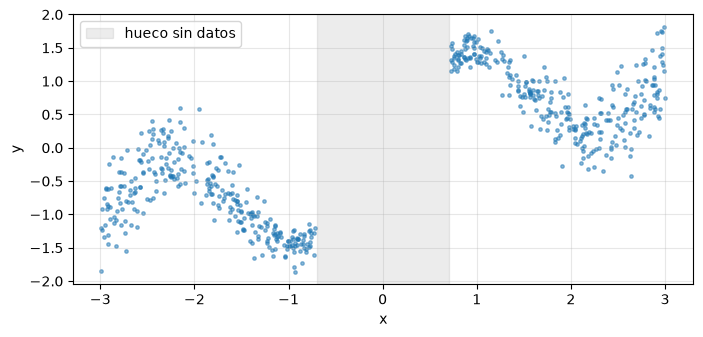

In [2]:
def generar_datos(n=600):
    # datos en dos bandas, con un hueco en el medio y ruido creciente con x
    x1 = np.random.uniform(-3, -0.7, n // 2)
    x2 = np.random.uniform(0.7, 3, n // 2)
    x = np.concatenate([x1, x2])
    sigma = 0.05 + 0.12 * np.abs(x)         # ruido heterocedástico
    y = np.sin(2 * x) + 0.5 * x + sigma * np.random.randn(len(x))
    return x.astype(np.float32), y.astype(np.float32)

x_train, y_train = generar_datos()
x_grid = np.linspace(-4.5, 4.5, 300, dtype=np.float32)

plt.figure(figsize=(8, 3.5))
plt.scatter(x_train, y_train, s=6, alpha=0.5)
plt.axvspan(-0.7, 0.7, color="gray", alpha=0.15, label="hueco sin datos")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

---
### Ejercicio 1: incerteza aleatórica — predecir la varianza

En vez de predecir solo $\hat y$, la red predice $\big(\mu(x), \log\sigma^2(x)\big)$ y se entrena maximizando la verosimilitud gaussiana, es decir minimizando:
$$\mathcal{L} = \frac{1}{N}\sum_i \left[ \frac{(y_i-\mu(x_i))^2}{2\sigma^2(x_i)} + \frac{1}{2}\log\sigma^2(x_i) \right]$$
¿Qué observan en la gráfica de $\mu(x) \pm 2\sigma(x)$? ¿la banda sigue al ruido de los datos? ¿Qué pasa en el hueco?

In [3]:
class RedProbabilistica(nn.Module):
    """Predice media y log-varianza; dropout activable para MC-Dropout."""
    def __init__(self, oculto=128, p_drop=0.1):
        super().__init__()
        self.tronco = nn.Sequential(
            nn.Linear(1, oculto), nn.ReLU(), nn.Dropout(p_drop),
            nn.Linear(oculto, oculto), nn.ReLU(), nn.Dropout(p_drop))
        self.mu = nn.Linear(oculto, 1)
        self.logvar = nn.Linear(oculto, 1)

    def forward(self, x):
        h = self.tronco(x.unsqueeze(-1))
        return self.mu(h).squeeze(-1), self.logvar(h).squeeze(-1)

def nll_gaussiana(y, mu, logvar):
    #@ (y - mu)^2 / (2 sigma^2) + 0.5 * log sigma^2, promediado
    return (((y - mu) ** 2) / (2 * torch.exp(logvar)) + 0.5 * logvar).mean()

NLL final: -0.823


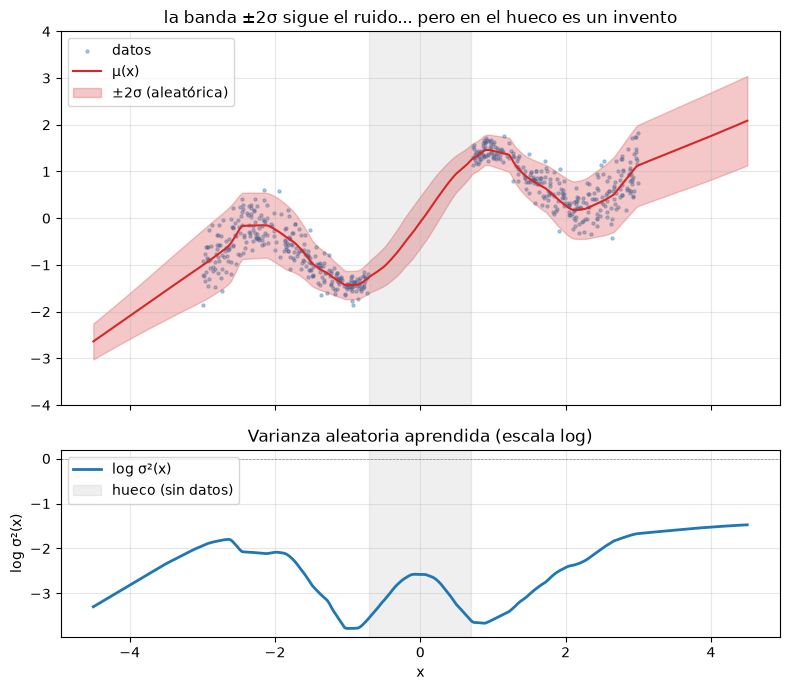

In [7]:
import numpy as np
import torch
import matplotlib.pyplot as plt

torch.manual_seed(SEED)
red = RedProbabilistica().to(device)
opt = torch.optim.Adam(red.parameters(), lr=1e-3)
X = torch.tensor(x_train).to(device); Y = torch.tensor(y_train).to(device)

red.train()
for paso in range(3000):
    opt.zero_grad()
    mu, logvar = red(X)  # forward
    loss = nll_gaussiana(Y, mu, logvar)
    loss.backward(); opt.step()
print(f"NLL final: {loss.item():.3f}")

red.eval()
with torch.no_grad():
    mu_g, logvar_g = red(torch.tensor(x_grid).to(device))
mu_g     = mu_g.cpu().numpy()
logvar_g = logvar_g.cpu().numpy()
sigma_g  = np.exp(0.5 * logvar_g)

# --- Dos paneles apilados, mismo eje x ---
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(8, 7), sharex=True,
    gridspec_kw={"height_ratios": [2, 1]}
)

# === Panel superior: tu gráfico original ===
ax1.scatter(x_train, y_train, s=5, alpha=0.35, label="datos")
ax1.plot(x_grid, mu_g, color="C3", label="μ(x)")
ax1.fill_between(x_grid, mu_g - 2 * sigma_g, mu_g + 2 * sigma_g,
                 color="C3", alpha=0.25, label="±2σ (aleatórica)")
ax1.axvspan(-0.7, 0.7, color="gray", alpha=0.12)
ax1.set_ylim(-4, 4)
ax1.legend(loc="upper left")
ax1.grid(alpha=0.3)
ax1.set_title("la banda ±2σ sigue el ruido... pero en el hueco es un invento")

# === Panel inferior: log σ²(x) ===
ax2.plot(x_grid, logvar_g, color="C0", lw=2, label="log σ²(x)")
ax2.axhline(0, color="k", lw=0.5, ls="--", alpha=0.4)   # referencia σ² = 1
ax2.axvspan(-0.7, 0.7, color="gray", alpha=0.12, label="hueco (sin datos)")
ax2.set_xlabel("x")
ax2.set_ylabel("log σ²(x)")
ax2.legend(loc="upper left")
ax2.grid(alpha=0.3)
ax2.set_title("Varianza aleatoria aprendida (escala log)")

plt.tight_layout()
plt.show()

entre -0.7 y 0.7 no tenia datos. Fijemenos que asume un desvio pequeño para falta  de datos, el modelo esta mintiendo y no refleja incerteza, no se dispara.

---
### Ejercicio 2: incerteza epistémica con MC-Dropout

Dejar el **dropout activo en inferencia** y hacer $T=100$ pasadas: la media de las $\mu_t$ es la predicción y su desvío estándar estima la **incerteza epistémica**. Implementarlo y graficar ambas bandas juntas: ¿dónde domina cada una?

*Ayuda: `model.train()` activa el dropout; también se puede recorrer los módulos y poner en modo train solo los `nn.Dropout`.*

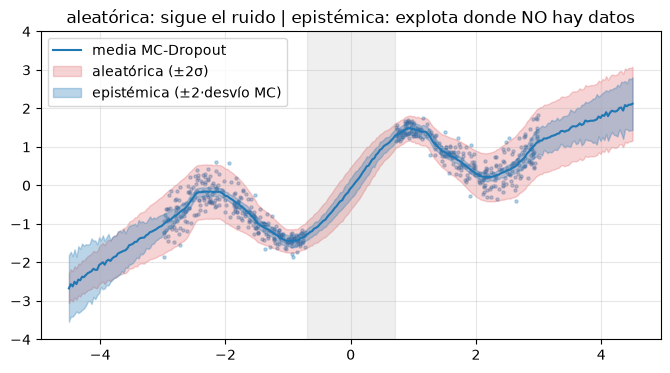

In [8]:
@torch.no_grad()
def mc_dropout(red, x, T=100):
    red.train()                          # dropout ON
    mus = []
    for _ in range(T):
        mu, _ = red(x)                   # ignora logvar
        mus.append(mu)
    mus = torch.stack(mus)               # (T, N)
    red.eval()                           # restaura modo evaluación
    return mus.mean(0), mus.std(0)       # (N,), (N,)

xg = torch.tensor(x_grid).to(device)
mu_ep, sd_ep = mc_dropout(red, xg)
mu_ep = mu_ep.cpu().numpy(); 
sd_ep = sd_ep.cpu().numpy()

plt.figure(figsize=(8, 4))
plt.scatter(x_train, y_train, s=5, alpha=0.3)
plt.plot(x_grid, mu_ep, color="C0", label="media MC-Dropout")
plt.fill_between(x_grid, mu_ep - 2 * sigma_g, mu_ep + 2 * sigma_g,
                 color="C3", alpha=0.2, label="aleatórica (±2σ)")
plt.fill_between(x_grid, mu_ep - 2 * sd_ep, mu_ep + 2 * sd_ep,
                 color="C0", alpha=0.3, label="epistémica (±2·desvío MC)")
plt.axvspan(-0.7, 0.7, color="gray", alpha=0.12)
plt.ylim(-4, 4); plt.legend(); plt.grid(alpha=0.3)
plt.title("aleatórica: sigue el ruido | epistémica: explota donde NO hay datos")
plt.show()

la epistemcia es la que depende de lo que sabe el modelo.  A mayor e sporque el modelo predice con mucho desvio ante la entrada. DOnde hay mas datos menor umbral.

---
## Parte 2: calibración en clasificación

Entrenamos una CNN chica en **FashionMNIST** (esto está provisto) y estudiamos si sus probabilidades son **honestas**.

In [26]:
from torchvision import datasets, transforms

fm_train = datasets.FashionMNIST("./data", train=True, download=True,
                                 transform=transforms.ToTensor())
fm_test = datasets.FashionMNIST("./data", train=False, download=True,
                                transform=transforms.ToTensor())
# train chico y MUCHAS épocas: receta para sobreajustar la NLL (=> sobreconfianza)
# + split de validación para calibrar
fm_train_sub = torch.utils.data.Subset(fm_train, range(4000))
fm_val_sub = torch.utils.data.Subset(fm_train, range(4000, 6000))
train_loader = DataLoader(fm_train_sub, batch_size=128, shuffle=True, num_workers=2)
val_loader = DataLoader(fm_val_sub, batch_size=256, num_workers=2)
test_loader = DataLoader(fm_test, batch_size=256, num_workers=2)

class MiniCNN(nn.Module):
    def __init__(self, p_drop=0.1):
        super().__init__()
        self.red = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Dropout(p_drop),
            nn.Linear(32 * 7 * 7, 128), nn.ReLU(), nn.Dropout(p_drop),
            nn.Linear(128, 10))
    def forward(self, x):
        return self.red(x)

def entrenar_cnn(semilla=0, epocas=30):
    torch.manual_seed(semilla)
    m = MiniCNN().to(device)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    ce = nn.CrossEntropyLoss()
    for ep in range(epocas):
        m.train()
        for Xb, yb in train_loader:
            Xb, yb = Xb.to(device), yb.to(device)
            opt.zero_grad(); ce(m(Xb), yb).backward(); opt.step()
    return m

@torch.no_grad()
def logits_de(modelo, loader):
    modelo.eval()
    L, Y = [], []
    for Xb, yb in loader:
        L.append(modelo(Xb.to(device)).cpu()) 
        Y.append(yb)
    return torch.cat(L), torch.cat(Y)

modelo = entrenar_cnn()
logits_test, y_test = logits_de(modelo, test_loader)
acc = (logits_test.argmax(1) == y_test).float().mean()
print(f"accuracy de test: {acc:.4f}")

accuracy de test: 0.8616


---
### Ejercicio 3: diagrama de confiabilidad y ECE

Implementar:
1. `diagrama_confiabilidad(probs, y, M=10)`: agrupar las predicciones en $M$ bins según su **confianza** (probabilidad máxima) y graficar exactitud vs. confianza por bin, junto con la diagonal ideal.
2. El **ECE** (error de calibración esperado):
$$ECE = \sum_{m} \frac{n_m}{N} \big| \mathrm{exac}(B_m) - \mathrm{conf}(B_m) \big|$$
¿La red es sobreconfiada o subconfiada?

In [32]:
# ====================== COMPLETAR ======================
# ========================================================

import torch
import numpy as np
import matplotlib.pyplot as plt

def diagrama_confiabilidad(probs, y, M=10):
    #M es cantidad de bins

    confianza, predicciones = probs.max(dim=1) #confianza: logit maximo, predicciones = posicion
    correctas = (predicciones ==y).float() #clase == prediccion

    confianza = confianza.cpu().numpy()
    correctas = correctas.cpu().numpy()

    limites = np.linspace(0, 1, M + 1) #discretizamos los bins.
    conf_bins = []
    acc_bins = []

    ECE = 0.0
    N = len(y)

    for m in range(M):

        if m==M -1:
            mascara = (confianza >= limites[m]) & (confianza <= limites[m+1])
        else:
            mascara = (confianza >= limites[m]) & (confianza < limites[m+1])

        n_m = mascara.sum() #sumo los totales de observacioens dentro del bin
        if n_m == 0:
            continue

        conf_m = confianza[mascara].mean() #confianza media
        acc_m = correctas[mascara].mean() #accuracy

        conf_bins.append(conf_m)
        acc_bins.append(acc_m)


        

        ECE += (n_m / N) * abs(acc_m - conf_m)

    plt.figure(figsize=(7, 7))

    plt.plot([0, 1], [0, 1], 
             linestyle="--", color="black", label="Calibración ideal")

    plt.plot(conf_bins, acc_bins, 
             marker="o", linewidth=2, label="CNN")

    plt.xlabel("Confianza promedio")
    plt.ylabel("Exactitud promedio")
    plt.title(f"Diagrama de confiabilidad (ECE = {ECE:.4f})")

    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()

    return ECE

    

0
1
2
0.26895767
0.22222222
3
0.3637459
0.3902439
4
0.45908266
0.451505
5
0.5504502
0.50276244
6
0.6501371
0.61648744
7
0.7515856
0.6680384
8
0.85384953
0.8056093
9
0.9849616
0.9650163


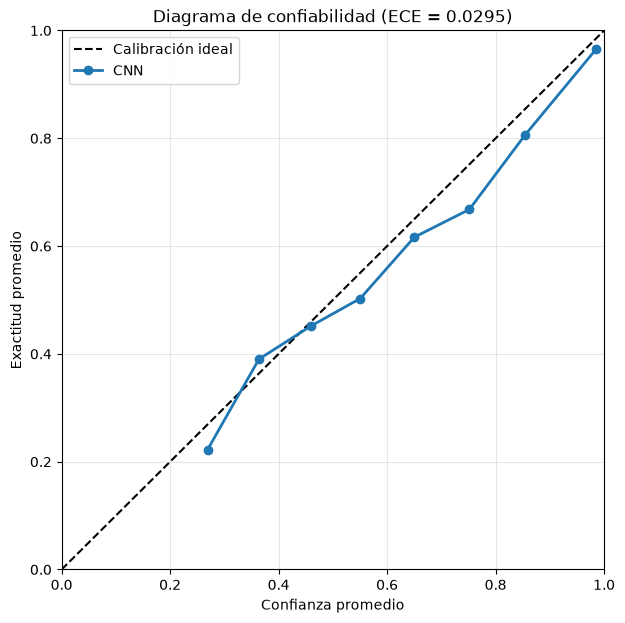

ECE: 0.0295


In [25]:
probs_test = torch.softmax(logits_test, dim=1)

ece = diagrama_confiabilidad(probs_test, y_test, M=10)

print(f"ECE: {ece:.4f}")

---
### Ejercicio 4: temperature scaling

Calibrar dividiendo los logits por una temperatura $T$: $p_i = \mathrm{softmax}(z_i / T)$.

- a) Ajustar $T$ minimizando la NLL sobre el conjunto de **validación** (un solo parámetro — se puede optimizar con Adam o LBFGS).
- b) Rehacer el diagrama de confiabilidad con $T$ óptima. Verificar que la **accuracy no cambia** (¿por qué?) y que el ECE baja.

In [28]:
logits_val, y_val = logits_de(modelo, val_loader)


#ya tenemos el modelo entrenado
#calculamos el valor de T con el conjutno de validaicon

T = torch.tensor([1.0], requires_grad=True)

optimizer = torch.optim.Adam([T], lr=0.01)
ce = nn.CrossEntropyLoss()

for i in range(1000):
    optimizer.zero_grad()
    loss = ce(logits_val / T, y_val)
    loss.backward()
    optimizer.step()

    # Queremos T > 0
    with torch.no_grad():
        T.clamp_(min=0.01)

print(T.item())

1.187869668006897


0
1
2
0.26445112
0.3846154
3
0.35973445
0.3809524
4
0.45991415
0.47229552
5
0.55022395
0.5581761
6
0.64955676
0.64083457
7
0.7517438
0.7275862
8
0.85287297
0.82955575
9
0.982485
0.975653


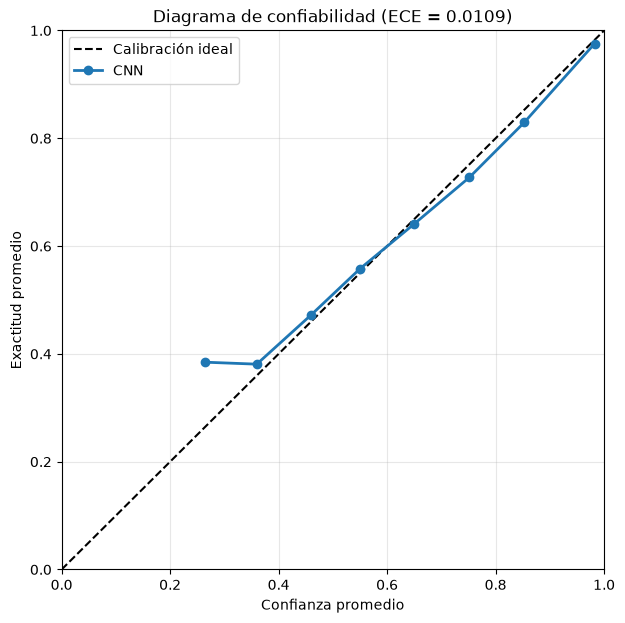

0.010894636934995653


In [29]:
T_opt = T.item()

probs_test_calibradas = torch.softmax(
    logits_test / T_opt,
    dim=1
)

ece_calibrado = diagrama_confiabilidad(
    probs_test_calibradas,
    y_test,
    M=10
)

print(ece_calibrado)

---
## Parte 3: MC-Dropout y ensambles en clasificación

### Ejercicio 5: comparar métodos

- a) **MC-Dropout**: con la misma CNN (tiene dropout), promediar las probabilidades de $T=30$ pasadas estocásticas. Calcular accuracy y ECE.
- b) **Deep ensemble**: entrenar $M=3$ CNNs con semillas distintas y promediar sus probabilidades. Calcular accuracy y ECE.
- c) Armar una tabla comparativa: softmax crudo, temperature scaling, MC-Dropout, ensamble.

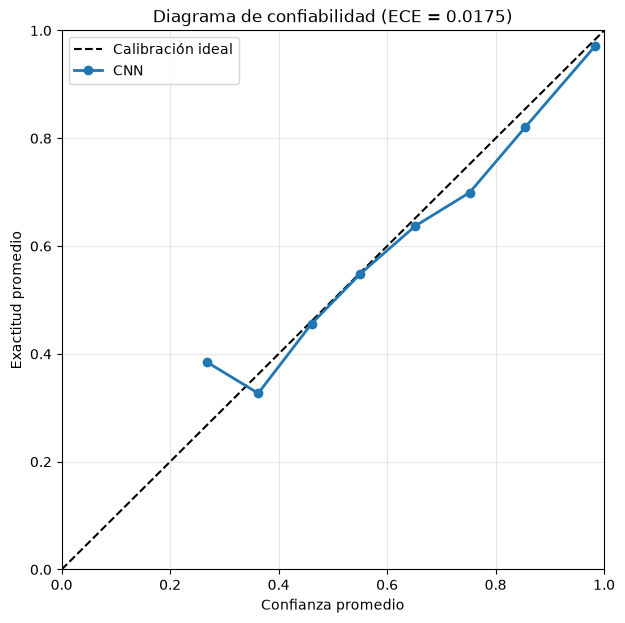

Accuracy MC-Dropout: 0.8605999946594238
ECE MC-Dropout: 0.01748699018359184


In [33]:
@torch.no_grad()
def mc_dropout(modelo, loader, T=30):
    modelo.eval()

    # Activamos solamente los Dropout
    for modulo in modelo.modules():
        if isinstance(modulo, nn.Dropout):
            modulo.train() #sea solo eval pero train la isntancia nn.dropout

    probabilidades = []

    for _ in range(T):
        probs = []

        for Xb, yb in loader:
            Xb = Xb.to(device)

            logits = modelo(Xb)
            probs.append(torch.softmax(logits, dim=1).cpu())

        probabilidades.append(torch.cat(probs))

    probabilidades = torch.stack(probabilidades)

    # promedio de las 30 predicciones
    probs_promedio = probabilidades.mean(dim=0)

    return probs_promedio #probs promedio por todas las observaciones


probs_mc = mc_dropout(modelo, test_loader, T=30)

acc_mc = (probs_mc.argmax(1) == y_test).float().mean().item()
ece_mc = diagrama_confiabilidad(probs_mc, y_test, M=10)

print("Accuracy MC-Dropout:", acc_mc)
print("ECE MC-Dropout:", ece_mc)

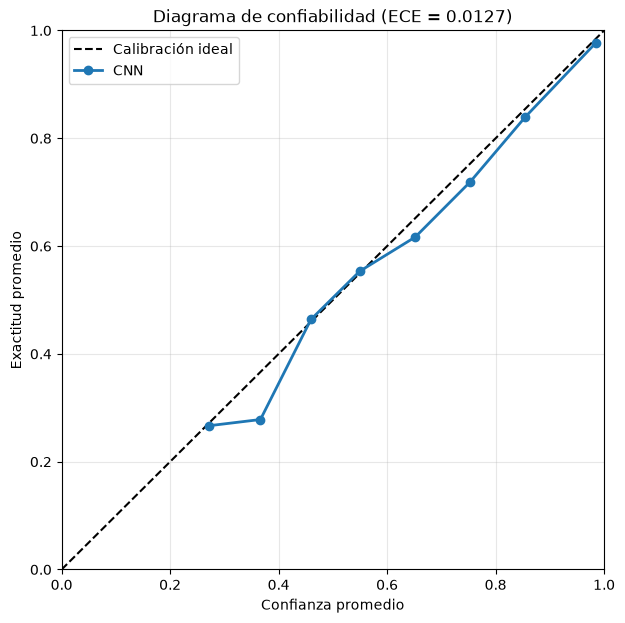

Accuracy: 0.8712000250816345
ECE: 0.01270493893623352


In [34]:
modelos = []

for semilla in [0, 1, 2]:
    modelo = entrenar_cnn(semilla=semilla)
    modelos.append(modelo)


probabilidades = []

for modelo in modelos:
    logits, y = logits_de(modelo, test_loader)
    probs = torch.softmax(logits, dim=1)
    probabilidades.append(probs)

probabilidades = torch.stack(probabilidades)
probs_ensemble = probabilidades.mean(dim=0)


acc_ensemble = (
    probs_ensemble.argmax(dim=1) == y_test
).float().mean().item()

ece_ensemble = diagrama_confiabilidad(
    probs_ensemble,
    y_test,
    M=10
)

print("Accuracy:", acc_ensemble)
print("ECE:", ece_ensemble)